In [1]:
%pylab inline
import gc
import anautil
import numpy as np
import scipy
import astropy.io.fits as pyfits
import astropy.io.ascii as ascii

import matplotlib.lines as mlines

from cosmosis.output.text_output import TextColumnOutput

import seaborn as sns
from matplotlib.colors import LogNorm, SymLogNorm

Populating the interactive namespace from numpy and matplotlib


In [2]:
cd /work/xiangchong.li/work/cosmicShear

/work/xiangchong.li/work/cosmicShear


# index

This notebook serves to read the correlation matrix of hscy1

In [3]:
def cov_coverter_hsc(ii):
    porm=ii//90 # 0 is xip 1 is xim
    if porm ==0:
        nperiod=9
        ii_eff=ii
        pad=0
    elif porm==1:
        nperiod=8
        ii_eff=ii-90
        pad=9
    jj= ii_eff//nperiod
    ji= ii_eff%nperiod
    return jj*17+pad+ji

def plot_cov(covIn):
    fig=plt.figure(figsize=(7,6))
    norm=SymLogNorm(linthresh=1e-13,vmin=-1e-10,vmax=1e-10)
    ax=sns.heatmap(covIn,cmap="RdBu",norm=norm, square=True,)
    ax.invert_yaxis()
    ax.set_xticks(np.arange(0,170,20))
    ax.set_xticklabels([str(i) for i in np.arange(0,170,20)])
    ax.set_yticks(np.arange(0,170,20))
    ax.set_yticklabels([str(i) for i in np.arange(0,170,20)])
    return

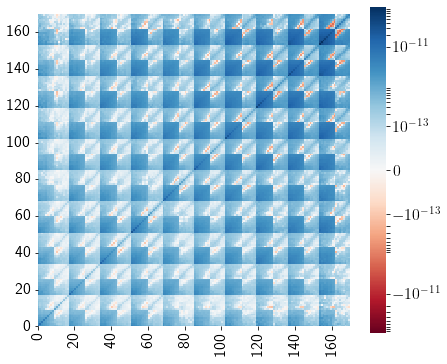

In [4]:
dd=np.loadtxt('data-hscy1/hsc16a_cstpcf_h2020.cov')
cov0=np.empty((170,170))
for j in range(170):
    for i in range(j,170):
        cov0[j,i]=dd[j*170+i]
        cov0[i,j]=cov0[j,i]
plot_cov(cov0)

In [5]:
cov=np.empty((170,170))
for j in range(170):
    for i in range(170):
        j2=cov_coverter_hsc(j)
        i2=cov_coverter_hsc(i)
        cov[j,i]=cov0[j2,i2]

In [6]:
xip=np.loadtxt('data-hscy1/hsc16a_cstpcf_h2020.xip')
xim=np.loadtxt('data-hscy1/hsc16a_cstpcf_h2020.xim')
dlogr1=np.average(np.log(xip[:,0])[1:]-np.log(xip[:,0])[:-1])
dlogr2=np.average((np.log(xim[:,0])[1:]-np.log(xim[:,0])[:-1]))
logr1=np.log(xip[:,0])
logr2=np.log(xim[:,0])
len(logr1)

9

In [10]:
ver='_bin2dp'
Dir='mockana/mock/meadcb1%s/' %ver
ofname='data-hscy1/meadcb1%s.fits' %ver
out=anautil.make_csdata_hdulist(Dir,logr1,logr2,cov)
out.writeto(ofname,overwrite=True)

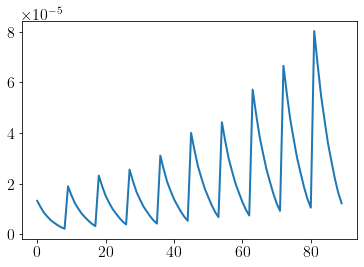

In [21]:
plt.plot(out[2].data['VALUE'])

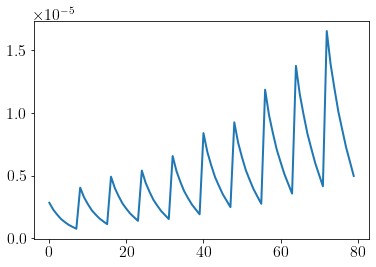

In [22]:
plt.plot(out[3].data['VALUE'])

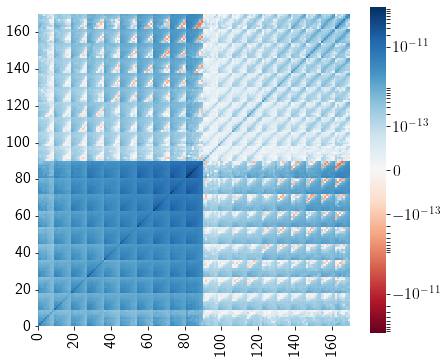

In [23]:
plot_cov(out[1].data)

In [24]:
mean=np.hstack([out[2].data['VALUE'],out[3].data['VALUE']])
cov=out[1].data
mockAll=np.random.multivariate_normal(mean, cov, 100)
plt.close()

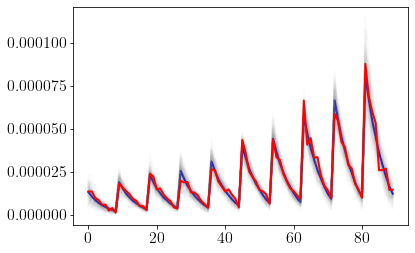

In [25]:
def run(i,out):
    outTmp=out.copy()
    outTmp[2].data['VALUE']=mockAll[i,:90]
    outTmp[3].data['VALUE']=mockAll[i,90:]
    return outTmp

plt.plot(out[2].data['VALUE'],c='blue')
for i in range(100):
    fnameTmp='data-hscy1/noisy/meadcb1%s-n%02d.fits' %(ver,i)
    out2=run(i,out)
    out2.writeto(fnameTmp,overwrite=True)
    plt.plot(out2[2].data['VALUE'],alpha=0.02,c='gray')
    del out2,fnameTmp
    gc.collect()
plt.plot(out[2].data['VALUE'],c='red')

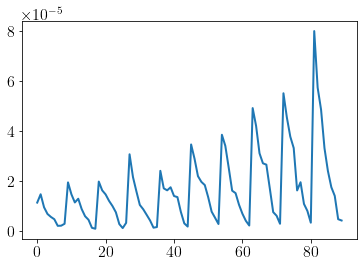

In [27]:
for i in range(1):
    fnameTmp='data-hscy1/noisy/meadcb1%s-n%02d.fits' %(ver,i)
    plt.plot(pyfits.getdata(fnameTmp,ext=2)['VALUE'])